1. run `winget install -e --id Gyan.FFmpeg` in cmd to install ffmpeg -> changing audio to .wav file
2. run `ffmpeg -i full_file_name -ac 1 -ar 44100 -c:a pcm_s16le file_name.wav` -> change audio file extension

In [33]:
# !ffmpeg -i hci_audio_record.m4a -ac 1 -ar 44100 -c:a pcm_s16le hci_audio_record.wav

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy import signal

In [12]:
fs, x = wavfile.read("hci_audio_record.wav")
t = np.arange(len(x)) / fs

print("fs =",fs)
print("Samples =",len(x))
print("Duration =",len(x)/fs,"s")


fs = 44100
Samples = 3753792
Duration = 85.12 s


Text(0, 0.5, 'amplitude')

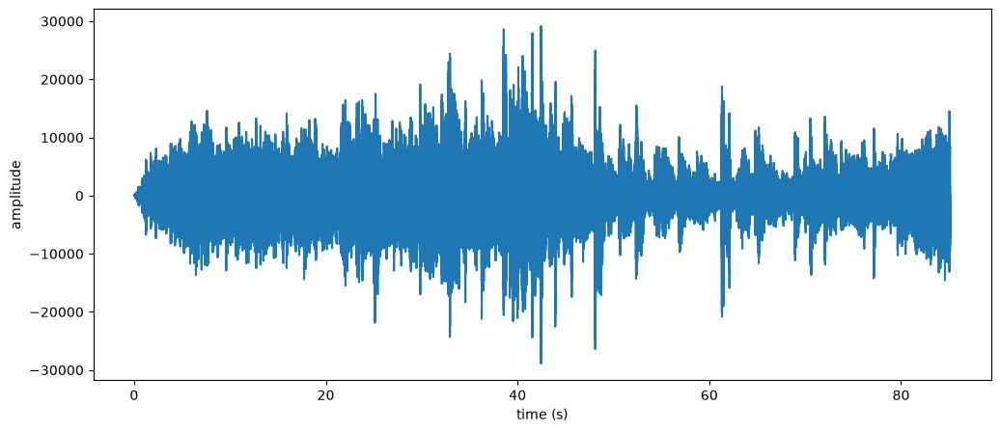

In [15]:
plt.figure(figsize = (12, 5))
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")

Text(0, 0.5, 'amplitude')

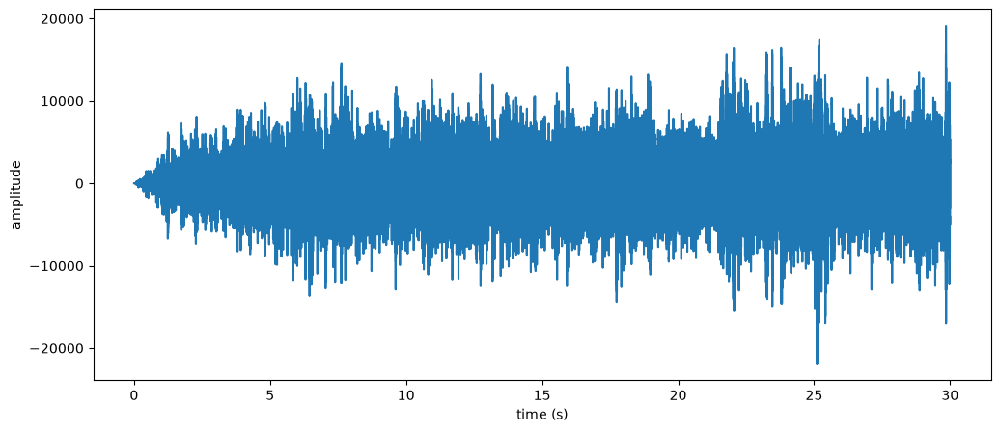

In [17]:
duration = 30
x_30_s = x[:fs*duration]
t_30_s = t[:fs*duration]

plt.figure(figsize = (12, 5))
plt.plot(t_30_s, x_30_s)
plt.xlabel("time (s)")
plt.ylabel("amplitude")

Text(0, 0.5, 'amplitude')

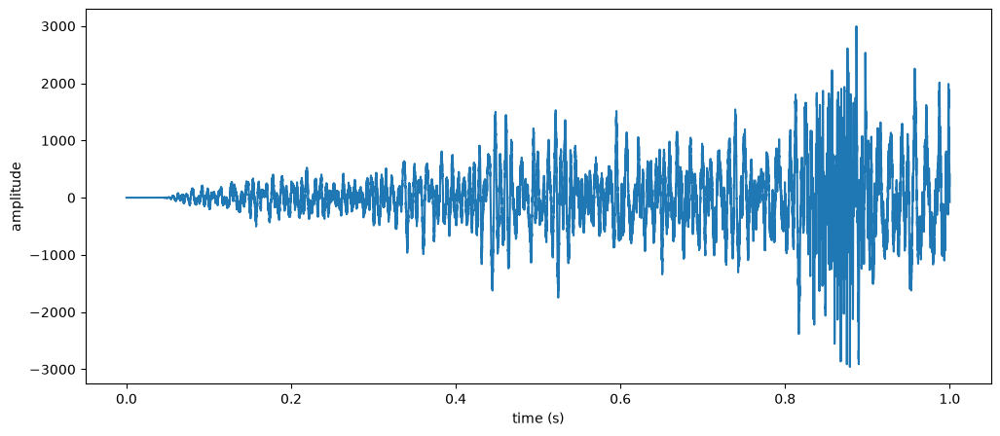

In [18]:
duration = 1
x_1_s = x[:fs*duration]
t_1_s = t[:fs*duration]

plt.figure(figsize = (12, 5))
plt.plot(t_1_s, x_1_s)
plt.xlabel("time (s)")
plt.ylabel("amplitude")

Text(0, 0.5, 'amplitude')

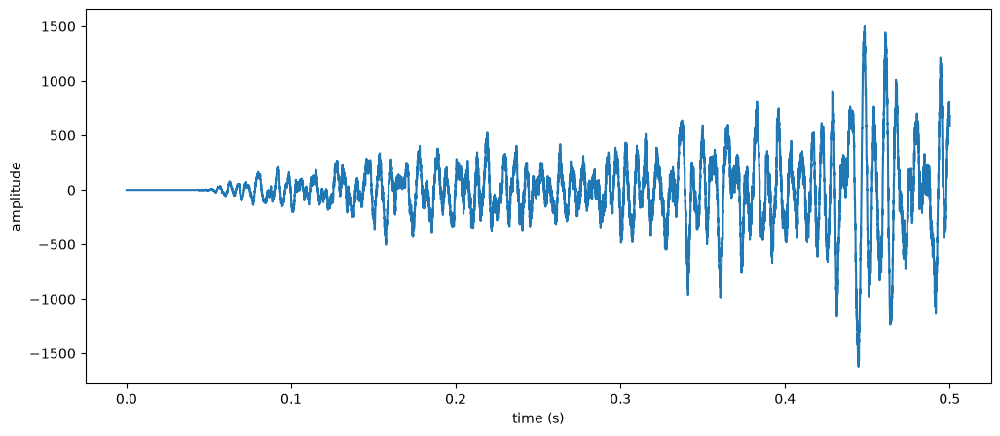

In [20]:
duration = 0.5
x_5_s = x[:int(fs*duration)]
t_5_s = t[:int(fs*duration)]

plt.figure(figsize = (12, 5))
plt.plot(t_5_s, x_5_s)
plt.xlabel("time (s)")
plt.ylabel("amplitude")

In [21]:
def spectrum(x, fs, nfft = -1):
    N = len(x)
    if nfft == -1:
        nfft = len(x)
    X = np.fft.fft(x, nfft)
    X = X[:N//2]
    mag = np.abs(X) *2/N
    freq= np.arange(len(mag)) * fs / N
    return freq, mag


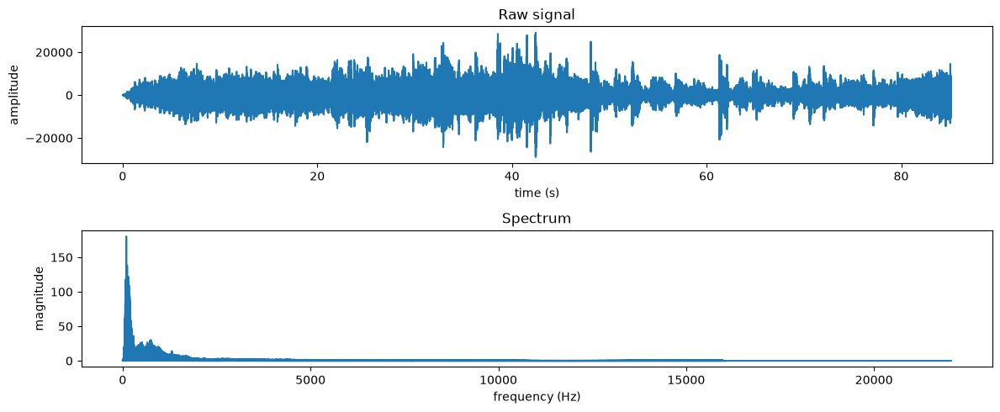

In [25]:
plt.figure(figsize = (12, 5))
plt.subplot(2, 1, 1); plt.plot(t, x); plt.title("Raw signal"); plt.xlabel("time (s)"); plt.ylabel("amplitude")

freq, mag = spectrum(x, fs)
plt.subplot(2, 1, 2); plt.plot(freq, mag); plt.title("Spectrum"); plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude")

plt.tight_layout()

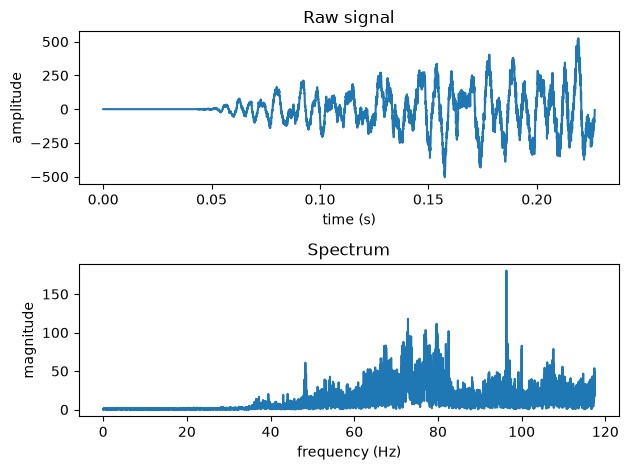

In [31]:
plt.subplot(2, 1, 1); plt.plot(t[:10000], x[:10000]); plt.title("Raw signal"); plt.xlabel("time (s)"); plt.ylabel("amplitude")

freq, mag = spectrum(x, fs)
plt.subplot(2, 1, 2); plt.plot(freq[:10000], mag[:10000]); plt.title("Spectrum"); plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude")
plt.tight_layout()

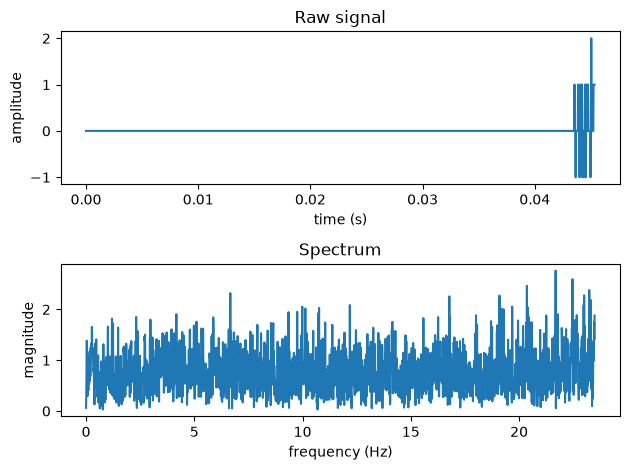

In [32]:
plt.subplot(2, 1, 1); plt.plot(t[:2000], x[:2000]); plt.title("Raw signal"); plt.xlabel("time (s)"); plt.ylabel("amplitude")

freq, mag = spectrum(x, fs)
plt.subplot(2, 1, 2); plt.plot(freq[:2000], mag[:2000]); plt.title("Spectrum"); plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude")
plt.tight_layout()

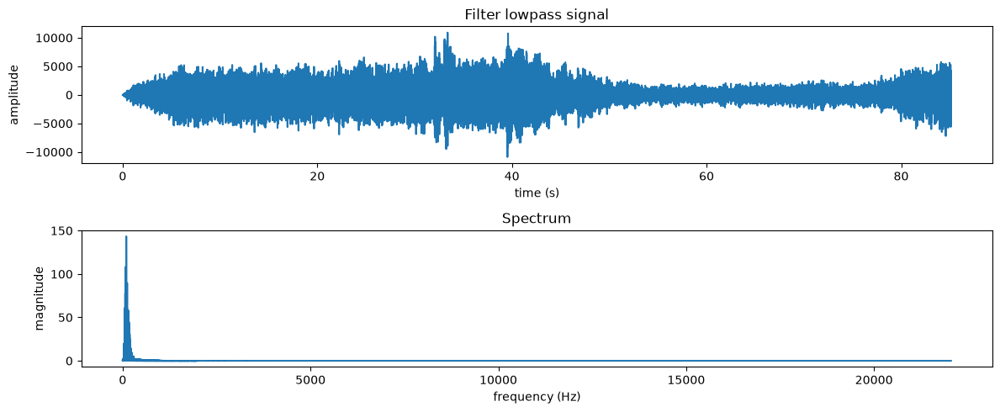

In [36]:
b, a = signal.butter(2, 20, fs=8000, btype="lowpass")
y = signal.lfilter(b, a, x)

plt.figure(figsize = (12, 5))
plt.subplot(2, 1, 1); plt.plot(t, y); plt.title("Filter lowpass signal"); plt.xlabel("time (s)"); plt.ylabel("amplitude")

freq, mag = spectrum(y, fs)
plt.subplot(2, 1, 2); plt.plot(freq, mag); plt.title("Spectrum"); plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude")

plt.tight_layout()


In [40]:
import IPython.display as ipd
print("Original")
ipd.display(ipd.Audio(x, rate=fs))

print("Lowpass filtered")
ipd.display(ipd.Audio(y, rate=fs))

Original


Lowpass filtered


In [38]:
# Original (convert to float so both are on the same scale)
x_f = x.astype(float)
x_f = x_f / np.max(np.abs(x_f))

# Filtered
y_f = y / np.max(np.abs(y))

print("Original")
ipd.display(ipd.Audio(x_f, rate=fs))

print("Lowpass filtered")
ipd.display(ipd.Audio(y_f, rate=fs))

Original


Lowpass filtered


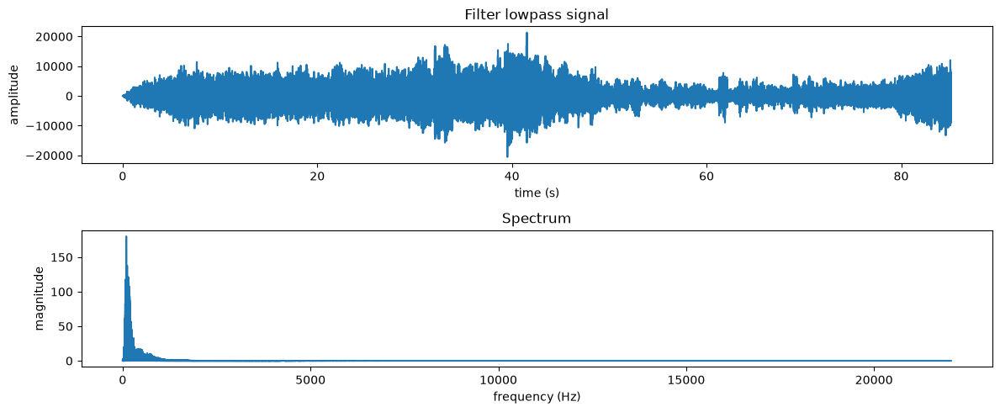

In [44]:
b, a = signal.butter(2, 20, fs=2000, btype="lowpass")
y = signal.lfilter(b, a, x)

plt.figure(figsize = (12, 5))
plt.subplot(2, 1, 1); plt.plot(t, y); plt.title("Filter lowpass signal"); plt.xlabel("time (s)"); plt.ylabel("amplitude")

freq, mag = spectrum(y, fs)
plt.subplot(2, 1, 2); plt.plot(freq, mag); plt.title("Spectrum"); plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude")

plt.tight_layout()


In [45]:
print("Original")
ipd.display(ipd.Audio(x, rate=fs))

print("Lowpass filtered")
ipd.display(ipd.Audio(y, rate=fs))

Original


Lowpass filtered


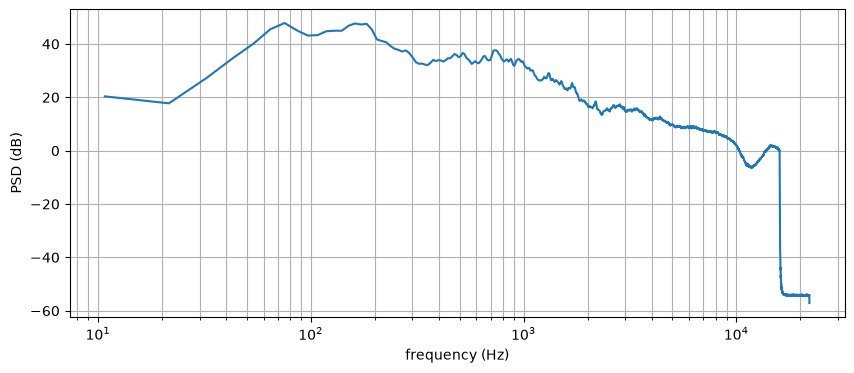

In [46]:
from scipy.signal import welch

f, P = welch(x.astype(float), fs=fs, nperseg=4096)
plt.figure(figsize=(10, 4))
plt.semilogx(f[1:], 10*np.log10(P[1:]))
plt.xlabel("frequency (Hz)"); plt.ylabel("PSD (dB)"); plt.grid(True, which="both")
plt.show()

In [47]:
c = np.cumsum(P) / np.sum(P)
print("99% of energy below", f[np.searchsorted(c, 0.99)], "Hz")

99% of energy below 2594.7509765625 Hz


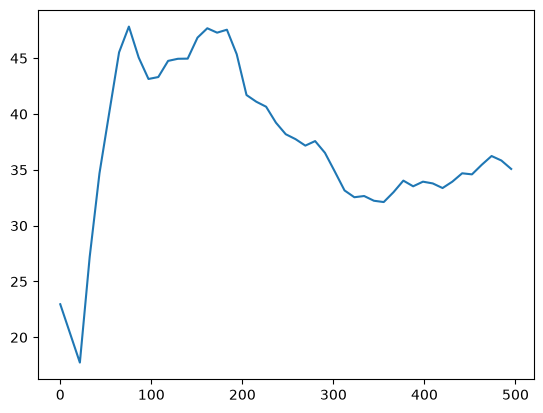

In [48]:
m = f < 500
plt.plot(f[m], 10*np.log10(P[m])); plt.show()

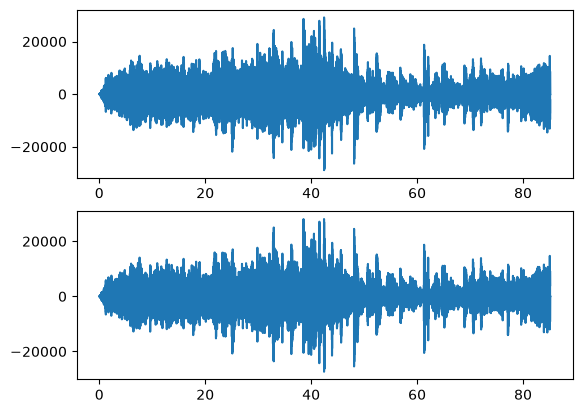

In [51]:
from scipy.signal import butter, sosfiltfilt

sos = butter(4, 70, btype="high", fs=fs, output="sos")
y_hp = sosfiltfilt(sos, x.astype(float))
plt.subplot(2, 1, 1); plt.plot(t, x)
plt.subplot(2, 1, 2); plt.plot(t, y_hp)

In [50]:
print("Original")
ipd.display(ipd.Audio(x, rate=fs))

print("Lowpass filtered")
ipd.display(ipd.Audio(y_hp, rate=fs))

Original


Lowpass filtered
